In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import xema

# Monthly national CPI by subclass (INE table 50905; the brief's 50937 is the annual one)
cpi = xema.download_cpi().set_index("date")
print(cpi.shape, cpi.index.min().date(), cpi.index.max().date(), cpi.isna().sum().sum())
# known values: olive oil +54.6 % and general CPI +3.1 % in December 2023
print(cpi.loc["2023-12-01", ["olive_oil_yoy", "general_yoy"]].to_dict())


(288, 8) 2002-01-01 2025-12-01 0
{'olive_oil_yoy': 54.6, 'general_yoy': 3.1}


In [2]:
# Rain in Catalonia: 10 XEMA stations (variable 1300, daily precipitation) in the
# agricultural comarques: Segria, Garrigues, Priorat, Baix Ebre, Tarragones
cat_stations = ["VK", "VH", "WK", "UM", "D1", "WJ", "U7", "DB", "VQ", "DK"]
cat = {}
for st in cat_stations:
    dd = xema.download_daily(st, "1300", "2002-01-01", "2025-12-31").set_index("date")["value"]
    mm = dd.resample("MS").agg(["sum", "count"])
    cat[st] = mm["sum"].where(mm["count"] >= 25)  # drop months with too few days
rain_cat = pd.DataFrame(cat).mean(axis=1)  # mean monthly total over the stations (mm)

# Rain in Andalusia (olive area): Open-Meteo reanalysis grid points near Jaen and Cordoba
sites = {"jaen": (37.77, -3.79), "cordoba": (37.89, -4.78)}
andalusia = {}
for name, (lat, lon) in sites.items():
    dd = xema.download_rain_openmeteo(name, lat, lon, "2002-01-01", "2025-12-31")
    andalusia[name] = dd.set_index("date")["value"].resample("MS").sum()
rain_and = pd.DataFrame(andalusia).mean(axis=1)

print(len(rain_cat), rain_cat.isna().sum(), rain_and.isna().sum())
print(pd.DataFrame({"Catalonia": rain_cat, "Andalusia": rain_and})
      .resample("YS").sum().round(0).rename(lambda d: d.year).T.to_string())


288 0 0
date        2002   2003   2004   2005   2006   2007   2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020   2021   2022   2023   2024   2025
Catalonia  419.0  597.0  407.0  433.0  343.0  381.0  539.0  420.0  428.0  428.0  410.0  518.0  547.0  369.0  404.0  313.0  598.0  352.0  586.0  470.0  358.0  285.0  567.0  516.0
Andalusia  532.0  642.0  493.0  269.0  583.0  484.0  614.0  642.0  933.0  534.0  519.0  583.0  526.0  384.0  578.0  371.0  758.0  380.0  454.0  463.0  519.0  348.0  605.0  719.0


In [3]:
def acc_anomaly(rain, months):
    # rain accumulated over the last `months` months, standardised per calendar month
    # (a simple SPI-like index: negative = drier than usual)
    acc = rain.rolling(months).sum()
    g = acc.groupby(acc.index.month)
    return (acc - g.transform("mean")) / g.transform("std")


z12 = pd.DataFrame({"Andalusia": acc_anomaly(rain_and, 12),
                    "Catalonia": acc_anomaly(rain_cat, 12)})
z24 = pd.DataFrame({"Andalusia": acc_anomaly(rain_and, 24),
                    "Catalonia": acc_anomaly(rain_cat, 24)})
print(z24.loc["2023-12-01"].round(2).to_dict(), z12.loc["2023-12-01"].round(2).to_dict())


{'Andalusia': -1.02, 'Catalonia': -2.12} {'Andalusia': -1.32, 'Catalonia': -1.73}


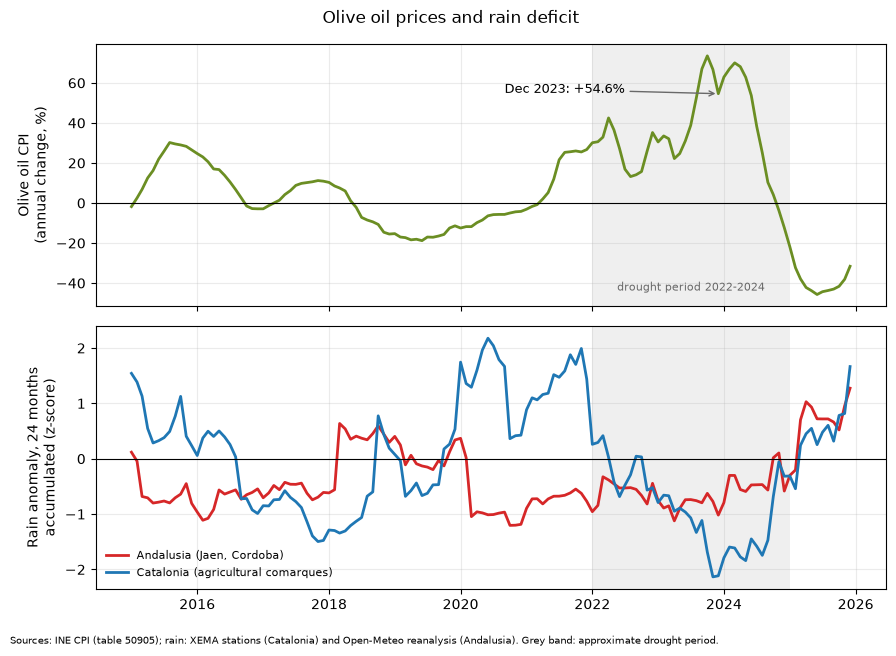

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
drought = (pd.Timestamp("2022-01-01"), pd.Timestamp("2024-12-31"))
start = "2015-01-01"

p = cpi.loc[start:, "olive_oil_yoy"]
ax1.plot(p.index, p, color="olivedrab", lw=2)
ax1.axhline(0, color="black", lw=0.8)
ax1.set_ylabel("Olive oil CPI\n(annual change, %)")
peak = p.loc["2023-12-01"]
ax1.annotate(f"Dec 2023: +{peak:.1f}%", xy=(pd.Timestamp("2023-12-01"), peak),
             xytext=(pd.Timestamp("2020-09-01"), 55), fontsize=9,
             arrowprops=dict(arrowstyle="->", color="dimgrey"))

ax2.plot(z24.loc[start:].index, z24.loc[start:, "Andalusia"], color="tab:red", lw=2,
         label="Andalusia (Jaen, Cordoba)")
ax2.plot(z24.loc[start:].index, z24.loc[start:, "Catalonia"], color="tab:blue", lw=2,
         label="Catalonia (agricultural comarques)")
ax2.axhline(0, color="black", lw=0.8)
ax2.set_ylabel("Rain anomaly, 24 months\naccumulated (z-score)")
ax2.legend(frameon=False, fontsize=8, loc="lower left")

for ax in (ax1, ax2):
    ax.axvspan(*drought, color="grey", alpha=0.12, lw=0)
    ax.grid(alpha=0.25)
ax1.text(drought[0] + (drought[1] - drought[0]) / 2, 0.05, "drought period 2022-2024",
         transform=ax1.get_xaxis_transform(), ha="center", va="bottom", fontsize=8,
         color="dimgrey")
fig.suptitle("Olive oil prices and rain deficit")
fig.text(0.01, 0.005,
         "Sources: INE CPI (table 50905); rain: XEMA stations (Catalonia) and Open-Meteo "
         "reanalysis (Andalusia). Grey band: approximate drought period.",
         fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.03, 1, 1))

out = Path("..") / "figures"
out.mkdir(exist_ok=True)
fig.savefig(out / "idea4_olive_oil_vs_drought.png", dpi=200)
fig.savefig(out / "idea4_olive_oil_vs_drought.svg")


   window      rain            price  lag_of_min_r  min_r  r_lag0
12 months Andalusia        Olive oil             7  -0.35   -0.21
12 months Andalusia      Fresh fruit            13  -0.26    0.09
12 months Andalusia Fresh vegetables            14  -0.19   -0.12
12 months Catalonia        Olive oil             3  -0.29   -0.28
12 months Catalonia      Fresh fruit             8  -0.23    0.17
12 months Catalonia Fresh vegetables            12  -0.13    0.02
24 months Andalusia        Olive oil             0  -0.35   -0.35
24 months Andalusia      Fresh fruit             5  -0.17   -0.14
24 months Andalusia Fresh vegetables            21  -0.31   -0.21
24 months Catalonia        Olive oil             0  -0.29   -0.29
24 months Catalonia      Fresh fruit             5  -0.14   -0.05
24 months Catalonia Fresh vegetables             0  -0.09   -0.09


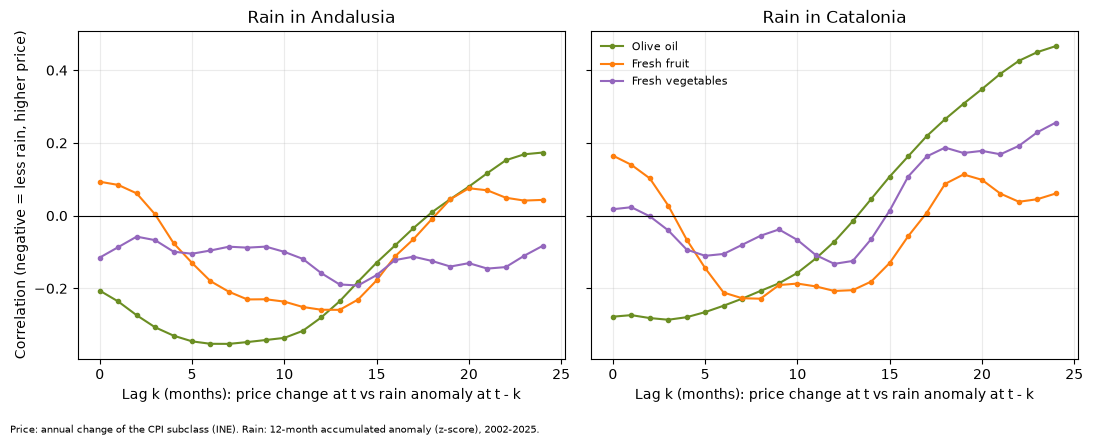

In [5]:
prices = {"Olive oil": cpi["olive_oil_yoy"], "Fresh fruit": cpi["fresh_fruit_yoy"],
          "Fresh vegetables": cpi["fresh_vegetables_yoy"]}
colors = {"Olive oil": "olivedrab", "Fresh fruit": "tab:orange", "Fresh vegetables": "tab:purple"}
lags = list(range(0, 25))


def lag_corr(price, z):
    # correlation between the price change at t and the rain anomaly at t - k
    return [price.corr(z.shift(k)) for k in lags]


fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, region in zip(axes, ["Andalusia", "Catalonia"]):
    for label, s in prices.items():
        ax.plot(lags, lag_corr(s, z12[region]), marker="o", ms=3, color=colors[label],
                label=label)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("Lag k (months): price change at t vs rain anomaly at t - k")
    ax.set_title(f"Rain in {region}")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Correlation (negative = less rain, higher price)")
axes[1].legend(frameon=False, fontsize=8)
fig.text(0.01, 0.005,
         "Price: annual change of the CPI subclass (INE). Rain: 12-month accumulated anomaly "
         "(z-score), 2002-2025.", fontsize=7, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(out / "idea4_lagged_correlation.png", dpi=200)
fig.savefig(out / "idea4_lagged_correlation.svg")

# most negative correlation (the expected sign) for both accumulation windows
rows = []
for window, zz in (("12 months", z12), ("24 months", z24)):
    for region in ["Andalusia", "Catalonia"]:
        for label, s in prices.items():
            r = lag_corr(s, zz[region])
            k = int(np.argmin(r))
            rows.append({"window": window, "rain": region, "price": label,
                         "lag_of_min_r": k, "min_r": round(r[k], 2), "r_lag0": round(r[0], 2)})
print(pd.DataFrame(rows).to_string(index=False))
